<a href="https://colab.research.google.com/github/Rajak20/Power_Consumption_Prediction/blob/main/Power_Consumption_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("powerconsumption.csv")

In [ ]:
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [ ]:
df.shape

(52416, 9)

In [ ]:
df.isnull().sum()

,0
Datetime,0
Temperature,0
Humidity,0
WindSpeed,0
GeneralDiffuseFlows,0
DiffuseFlows,0
PowerConsumption_Zone1,0
PowerConsumption_Zone2,0
PowerConsumption_Zone3,0


In [ ]:
import pandas as pd

# Ensure df is loaded
try:
    df
except NameError:
    df = pd.read_csv('powerconsumption.csv')

# Define numeric columns
numeric_cols = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

# Assess duplicates and basic statistics
print(f"Total rows: {len(df)}")
print(f"Duplicate rows count: {df.duplicated().sum()}")
print("\n--- Summary Statistics to Check for Outliers or Invalid Values ---")
print(df[numeric_cols].describe())

Total rows: 52416
Duplicate rows count: 0

--- Summary Statistics to Check for Outliers or Invalid Values ---
        Temperature      Humidity     WindSpeed  GeneralDiffuseFlows  \
count  52416.000000  52416.000000  52416.000000         52416.000000   
mean      18.810024     68.259518      1.959489           182.696614   
std        5.815476     15.551177      2.348862           264.400960   
min        3.247000     11.340000      0.050000             0.004000   
25%       14.410000     58.310000      0.078000             0.062000   
50%       18.780000     69.860000      0.086000             5.035500   
75%       22.890000     81.400000      4.915000           319.600000   
max       40.010000     94.800000      6.483000          1163.000000   

       DiffuseFlows  PowerConsumption_Zone1  PowerConsumption_Zone2  \
count  52416.000000            52416.000000            52416.000000   
mean      75.028022            32344.970564            21042.509082   
std      124.210949         

### Observations on Data Quality:

1. **No Missing Values:** As shown in your previous checks, there are no null values (`df.isnull().sum()` is all zero), which is excellent!
2. **Datetime Column:** The `Datetime` column is currently a string/object type. We should convert it to a pandas `datetime` format. This will allow us to extract highly predictive temporal features like **Hour**, **Day of Week**, **Month**, and **Is_Weekend**.
3. **Duplicates and Outliers:** The code cell above checks for duplicates and displays summary statistics to see if there are impossible values (such as negative wind speed, extreme humidity, or extreme power spikes).

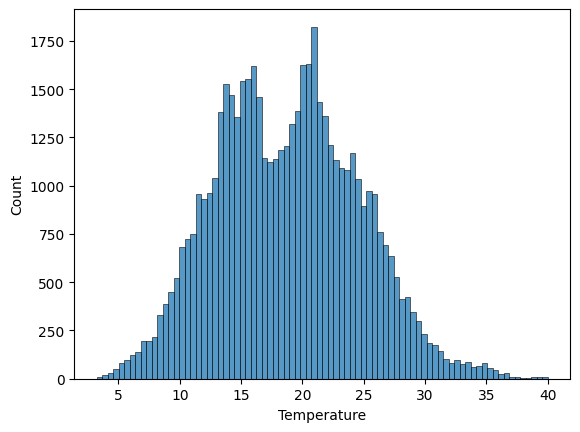

In [ ]:
sns.histplot(df['Temperature'])
plt.show()

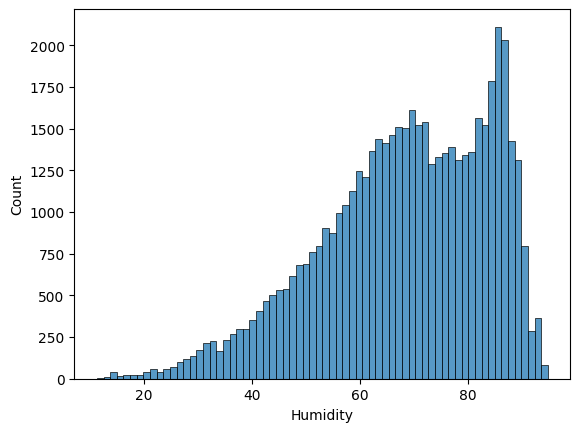

In [ ]:
sns.histplot(df['Humidity'])
plt.show()

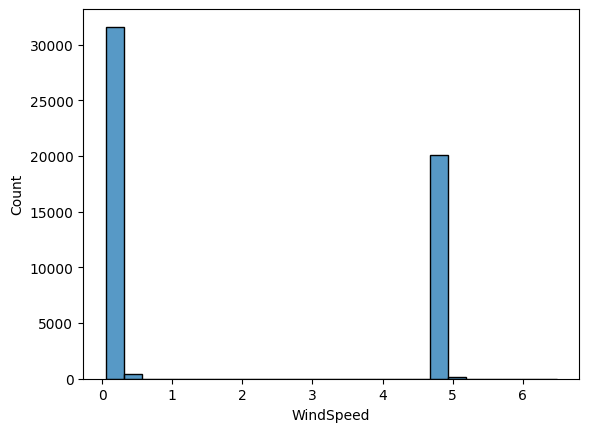

In [ ]:
sns.histplot(df['WindSpeed'])
plt.show()

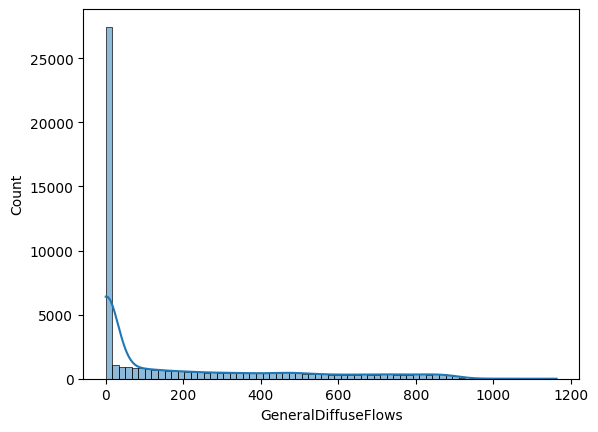

In [ ]:
sns.histplot(df['GeneralDiffuseFlows'],kde=True)
plt.show()

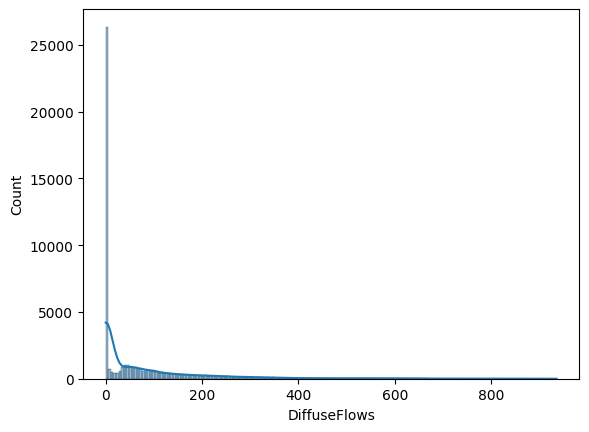

In [ ]:
sns.histplot(df['DiffuseFlows'],kde=True)
plt.show()

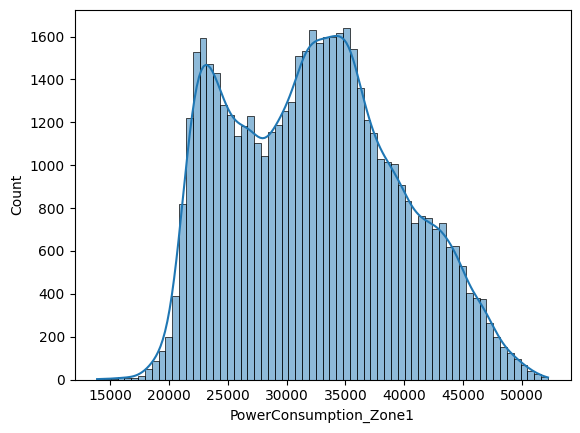

In [ ]:
sns.histplot(df['PowerConsumption_Zone1'],kde=True)
plt.show()

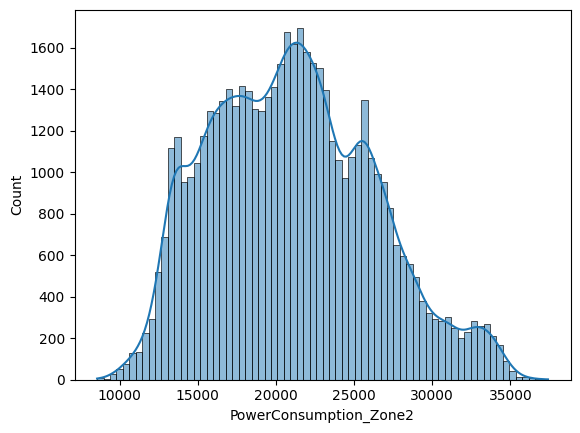

In [ ]:
sns.histplot(df['PowerConsumption_Zone2'],kde=True)
plt.show()

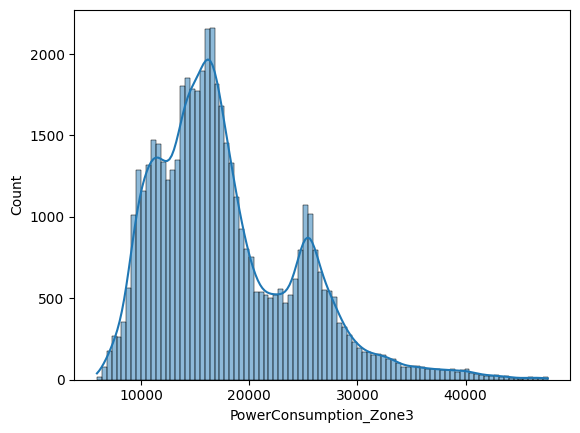

In [ ]:
sns.histplot(df['PowerConsumption_Zone3'],kde=True)
plt.show()

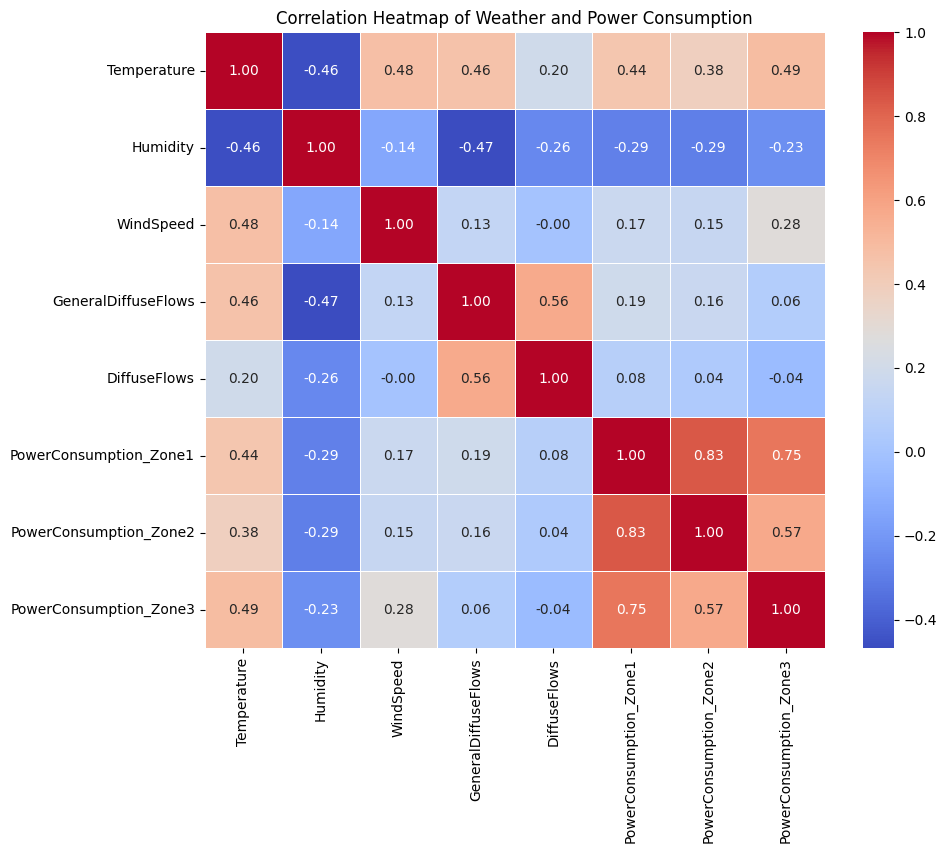

In [ ]:
# Calculate the correlation matrix for the numeric features
numeric_cols = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']
corr_matrix = df[numeric_cols].corr()

# Plot the correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Weather and Power Consumption')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Define features (X) and target (y)
features = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows']
target = 'PowerConsumption_Zone1'

X = df[features]
y = df[target]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a Random Forest Regressor
model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error: {mae:.2f} kW")
print(f"R2 Score (Variance Explained): {r2:.2f}")

Mean Absolute Error: 3236.22 kW
R2 Score (Variance Explained): 0.57


### Step 1: Data Enrichment (Cleaning and Parsing Datetime)
We will convert the `Datetime` column to a pandas datetime object and extract temporal features.

In [ ]:
# Convert to datetime format
df['Datetime'] = pd.to_datetime(df['Datetime'])

# Extract temporal features
df['Hour'] = df['Datetime'].dt.hour
df['Month'] = df['Datetime'].dt.month
df['DayOfWeek'] = df['Datetime'].dt.dayofweek
df['IsWeekend'] = df['DayOfWeek'].apply(lambda x: 1 if x >= 5 else 0)

# Display the new columns
display(df[['Datetime', 'Hour', 'Month', 'DayOfWeek', 'IsWeekend']].head())

,Datetime,Hour,Month,DayOfWeek,IsWeekend
0,2017-01-01 00:00:00,0,1,6,1
1,2017-01-01 00:10:00,0,1,6,1
2,2017-01-01 00:20:00,0,1,6,1
3,2017-01-01 00:30:00,0,1,6,1
4,2017-01-01 00:40:00,0,1,6,1


### Step 2: Training the Improved Model with New Features
Now we re-train our Random Forest Regressor including these new temporal features to see the improvement in predicting `PowerConsumption_Zone1`.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Define the new expanded feature set
enriched_features = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows',
                     'Hour', 'Month', 'DayOfWeek', 'IsWeekend']

X_enriched = df[enriched_features]
y_enriched = df['PowerConsumption_Zone1']

# Split data using the same split
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
    X_enriched, y_enriched, test_size=0.2, random_state=42
)

# Train Random Forest Regressor
improved_model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
improved_model.fit(X_train_e, y_train_e)

# Predict and Evaluate
y_pred_e = improved_model.predict(X_test_e)
mae_e = mean_absolute_error(y_test_e, y_pred_e)
r2_e = r2_score(y_test_e, y_pred_e)

print(f"--- Comparison ---")
print(f"Previous R2 Score: 0.57")
print(f"Improved R2 Score: {r2_e:.4f}")
print(f"Previous MAE: 3236.22 kW")
print(f"Improved MAE: {mae_e:.2f} kW")

--- Comparison ---
Previous R2 Score: 0.57
Improved R2 Score: 0.9776
Previous MAE: 3236.22 kW
Improved MAE: 710.93 kW


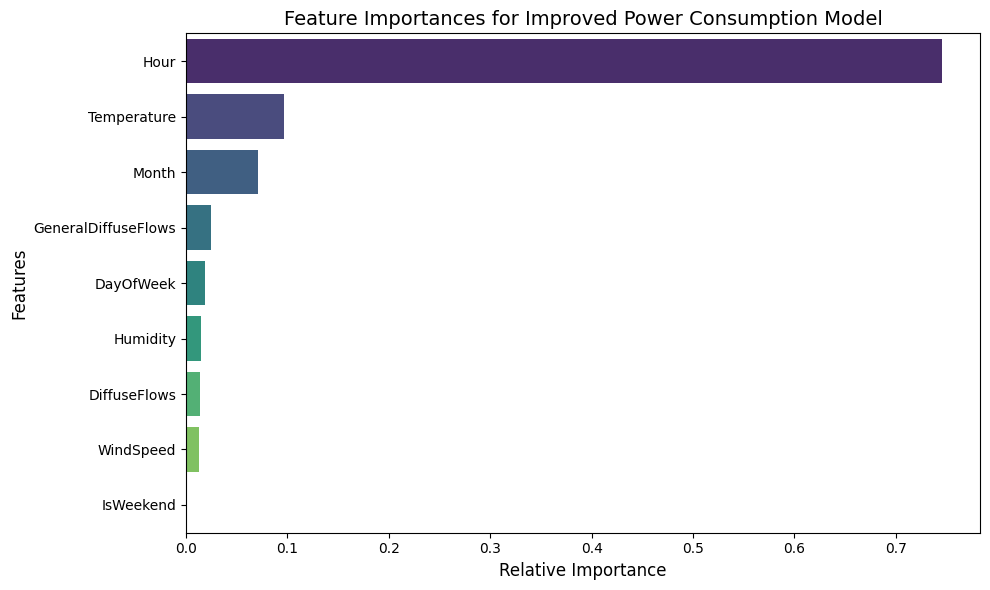

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importances from the trained improved model
importances = improved_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Map importances to corresponding feature names
feature_names = np.array(enriched_features)

# Plot feature importances without FutureWarning
plt.figure(figsize=(10, 6))
sns.barplot(
    x=importances[indices],
    y=feature_names[indices],
    hue=feature_names[indices],
    palette='viridis',
    legend=False
)
plt.title('Feature Importances for Improved Power Consumption Model', fontsize=14)
plt.xlabel('Relative Importance', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()

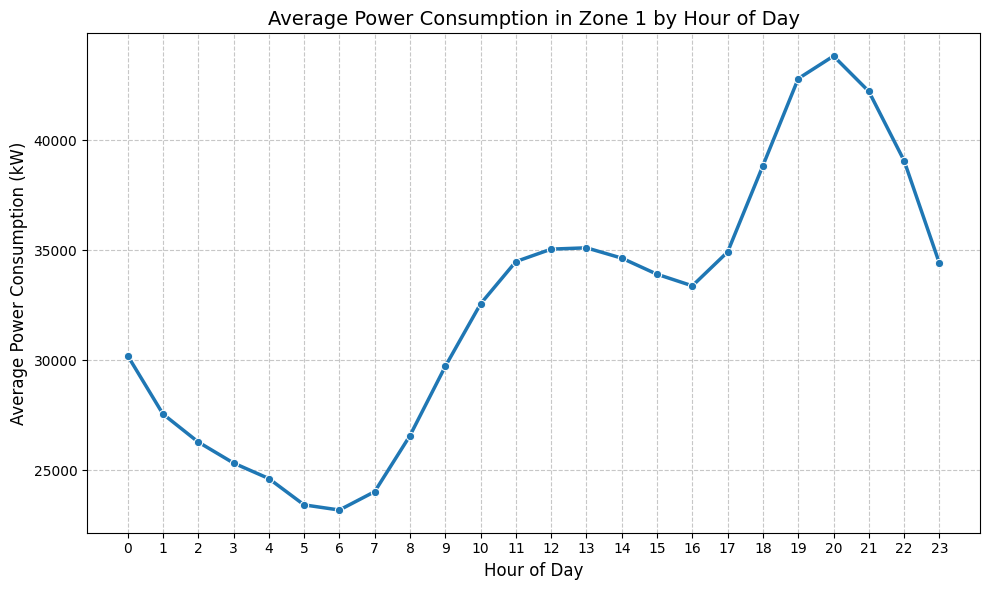

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Hour to calculate mean power consumption
hourly_power = df.groupby('Hour')['PowerConsumption_Zone1'].mean().reset_index()

# Create the line plot
plt.figure(figsize=(10, 6))
sns.lineplot(data=hourly_power, x='Hour', y='PowerConsumption_Zone1', marker='o', color='tab:blue', linewidth=2.5)
plt.title('Average Power Consumption in Zone 1 by Hour of Day', fontsize=14)
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Average Power Consumption (kW)', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Step 3: Comparing Model Performance Across Different Zones
We will evaluate model predictions for all three target zones (`PowerConsumption_Zone1`, `PowerConsumption_Zone2`, and `PowerConsumption_Zone3`) using both the baseline weather features and our newly engineered temporal features.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Define the targets
targets = ['PowerConsumption_Zone1', 'PowerConsumption_Zone2', 'PowerConsumption_Zone3']

# Define the feature sets
baseline_features = ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows']
enriched_features = baseline_features + ['Hour', 'Month', 'DayOfWeek', 'IsWeekend']

results = []

for target in targets:
    # 1. Baseline Model (Weather features only)
    X_base = df[baseline_features]
    y = df[target]
    X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
        X_base, y, test_size=0.2, random_state=42
    )

    base_model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    base_model.fit(X_train_b, y_train_b)
    y_pred_b = base_model.predict(X_test_b)

    base_mae = mean_absolute_error(y_test_b, y_pred_b)
    base_r2 = r2_score(y_test_b, y_pred_b)

    # 2. Enriched Model (Weather + Temporal features)
    X_enr = df[enriched_features]
    X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(
        X_enr, y, test_size=0.2, random_state=42
    )

    enr_model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    enr_model.fit(X_train_e, y_train_e)
    y_pred_e = enr_model.predict(X_test_e)

    enr_mae = mean_absolute_error(y_test_e, y_pred_e)
    enr_r2 = r2_score(y_test_e, y_pred_e)

    # Store results
    results.append({
        'Zone': target,
        'Baseline R2': base_r2,
        'Enriched R2': enr_r2,
        'Baseline MAE (kW)': base_mae,
        'Enriched MAE (kW)': enr_mae
    })

# Create summary DataFrame
comparison_df = pd.DataFrame(results)
display(comparison_df)

,Zone,Baseline R2,Enriched R2,Baseline MAE (kW),Enriched MAE (kW)
0,PowerConsumption_Zone1,0.568002,0.977630,3236.218301,710.929428
1,PowerConsumption_Zone2,0.569131,0.979213,2389.151227,497.024413
2,PowerConsumption_Zone3,0.709679,0.986846,2466.508581,473.020543


### Step 4: Predict Power Consumption for a Specific Hour
We will create a helper function that allows us to predict the power consumption for Zone 1 at any specific hour, using average dataset metrics for the remaining variables as defaults.

In [ ]:
def predict_zone1_power(hour, temp=None, humidity=None, wind_speed=None, gen_diffuse=None, diffuse=None, month=6, day_of_week=2, is_weekend=0):
    # Use mean values from the dataset if not specified
    temp = temp if temp is not None else df['Temperature'].mean()
    humidity = humidity if humidity is not None else df['Humidity'].mean()
    wind_speed = wind_speed if wind_speed is not None else df['WindSpeed'].mean()
    gen_diffuse = gen_diffuse if gen_diffuse is not None else df['GeneralDiffuseFlows'].mean()
    diffuse = diffuse if diffuse is not None else df['DiffuseFlows'].mean()

    # Prepare the feature array in the exact order as enriched_features
    # ['Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows', 'Hour', 'Month', 'DayOfWeek', 'IsWeekend']
    input_data = pd.DataFrame([[
        temp, humidity, wind_speed, gen_diffuse, diffuse, hour, month, day_of_week, is_weekend
    ]], columns=enriched_features)

    # Predict
    prediction = improved_model.predict(input_data)[0]
    return prediction

# Example: Predict power consumption at 7:00 PM (Hour 19)
target_hour = 19
predicted_power = predict_zone1_power(hour=target_hour)
print(f"Predicted Power Consumption for Zone 1 at {target_hour}:00 is {predicted_power:.2f} kW")

Predicted Power Consumption for Zone 1 at 19:00 is 42005.08 kW


### Step 5: Exporting the Models for Deployment
We will serialize the trained models to pickle (`.pkl`) files and use Colab's file helper to download them.

In [ ]:
import pickle
from google.colab import files

# Save the improved model to a pickle file
with open('improved_model_zone1.pkl', 'wb') as f:
    pickle.dump(improved_model, f)

print("Model successfully serialized to 'improved_model_zone1.pkl'")

# Trigger automatic download in the browser
files.download('improved_model_zone1.pkl')

Model successfully serialized to 'improved_model_zone1.pkl'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Diagnostic: Print exact features used to train the model
expected_features = [
    'Temperature',
    'Humidity',
    'WindSpeed',
    'GeneralDiffuseFlows',
    'DiffuseFlows',
    'Hour',
    'Month',
    'DayOfWeek',
    'IsWeekend'
]

print("--- Model Expectation Diagnostic ---")
print(f"The model expects exactly {len(expected_features)} features in this exact order:")
for i, col in enumerate(expected_features, 1):
    print(f"{i}. {col}")

print("\nTo make a prediction in your application, construct your input DataFrame like this:")
print("""python
import pandas as pd
import pickle

# Load the model
with open('improved_model_zone1.pkl', 'rb') as f:
    model = pickle.load(f)

# Input data MUST have these exact column names in this exact order
columns = [
    'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows',
    'Hour', 'Month', 'DayOfWeek', 'IsWeekend'
]

# Example values
input_df = pd.DataFrame([[
    25.0,  # Temperature
    60.0,  # Humidity
    1.5,   # WindSpeed
    150.0, # GeneralDiffuseFlows
    50.0,  # DiffuseFlows
    14,    # Hour
    6,     # Month
    2,     # DayOfWeek (2 = Wednesday)
    0      # IsWeekend (0 = No, 1 = Yes)
]], columns=columns)

prediction = model.predict(input_df)
print(f"Predicted Power Consumption: {prediction[0]:.2f} kW")
""")

--- Model Expectation Diagnostic ---
The model expects exactly 9 features in this exact order:
1. Temperature
2. Humidity
3. WindSpeed
4. GeneralDiffuseFlows
5. DiffuseFlows
6. Hour
7. Month
8. DayOfWeek
9. IsWeekend

To make a prediction in your application, construct your input DataFrame like this:
python
import pandas as pd
import pickle

# Load the model
with open('improved_model_zone1.pkl', 'rb') as f:
    model = pickle.load(f)

# Input data MUST have these exact column names in this exact order
columns = [
    'Temperature', 'Humidity', 'WindSpeed', 'GeneralDiffuseFlows', 'DiffuseFlows',
    'Hour', 'Month', 'DayOfWeek', 'IsWeekend'
]

# Example values
input_df = pd.DataFrame([[
    25.0,  # Temperature
    60.0,  # Humidity
    1.5,   # WindSpeed
    150.0, # GeneralDiffuseFlows
    50.0,  # DiffuseFlows
    14,    # Hour
    6,     # Month
    2,     # DayOfWeek (2 = Wednesday)
    0      # IsWeekend (0 = No, 1 = Yes)
]], columns=columns)

prediction = model.predict(input_df)
